# Розрахунково-графічна робота — варіант № 2
## Розділ 3. Моделювання IoT-моніторингу теплиці та Edge Computing

**Мета:** змоделювати покази сенсорів температури, вологості ґрунту, освітленості та pH на трьох ділянках; обробити некоректні вимірювання, записати дані у реляційну SQLite, порівняти gzip/zlib/bzip2, відправити **стиснений пакет** у Firebase Realtime Database та перевірити зворотне відновлення.

**Важливо:** це синтетичні дані, а інтервал pH 6,0–7,0 є умовним демонстраційним порогом, а не універсальною нормою для всіх культур.

**Перед запуском:** завантажте `greenhouse_edge.py` через ліву панель Files у `/content`. Для хмарного етапу окремо завантажте приватний JSON Firebase **лише в тимчасову сесію**, ніколи не публікуйте його на GitHub.

### 1. Підготовка бібліотек та файлів

In [1]:
!pip -q install numpy pandas matplotlib firebase-admin

In [4]:
from pathlib import Path
script = Path('/content/greenhouse_edge.py')
assert script.exists(), 'Завантажте greenhouse_edge.py у панелі Files'
print('Скрипт знайдено; підготовка завершена')

Скрипт знайдено; підготовка завершена


### 2. Локальна Edge-обробка, SQLite, статистика і стиснення

In [5]:
import subprocess, os
result = subprocess.run(['python', str(script)], cwd='/content', capture_output=True, text=True)
print(result.stdout[-3500:])
if result.returncode:
    print(result.stderr[-1500:])
assert result.returncode == 0, 'Перевірте помилку вище'

РГР - варіант 2. Звіт з моделювання теплиці
Записів у SQLite: 1095
Частка pH в умовному діапазоні 6,0-7,0: 96.35 %
Кореляція температура / вологість ґрунту: -0.532
Найкраще стиснення: bzip2

Сезонні середні:
        temperature_c  soil_moisture_pct  illuminance_lux  soil_ph
season                                                            
Весна           22.54              52.73         14966.98     6.52
Зима            10.52              60.16          5315.91     6.54
Літо            26.71              50.19         18204.14     6.53
Осінь           14.97              57.10          8500.39     6.52

Порівняння ділянок:
           temperature_c  soil_moisture_pct  illuminance_lux  soil_ph
site                                                                 
Ділянка A          17.98              51.98         12500.15     6.34
Ділянка B          18.93              54.73         11603.01     6.54
Ділянка C          19.31              58.33         11269.81     6.71

Стиснення:
{
  "gz

### 3. Перевірка очищення та реляційних зв’язків

In [6]:
import pandas as pd
import sqlite3
raw = pd.read_csv('/content/results/raw.csv')
clean = pd.read_csv('/content/results/cleaned.csv')
print('Пропуски до очищення:')
display(raw.isna().sum().to_frame('Кількість'))
print('Пропуски після очищення:')
display(clean.isna().sum().to_frame('Кількість'))
assert clean.isna().sum().sum() == 0
assert len(clean) == 1095
with sqlite3.connect('/content/results/greenhouse.sqlite') as con:
    print('Таблиці SQLite:')
    display(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", con))
    print('Зовнішній ключ вимірювань:')
    display(pd.read_sql_query('PRAGMA foreign_key_list(measurements)', con))
    print('Кількість записів:', con.execute('SELECT COUNT(*) FROM measurements').fetchone()[0])

Пропуски до очищення:


,Кількість
date,0
site,0
soil_moisture_pct,2
temperature_c,6
illuminance_lux,5
soil_ph,4


Пропуски після очищення:


,Кількість
date,0
site,0
soil_moisture_pct,0
temperature_c,0
illuminance_lux,0
soil_ph,0
season,0
ph_optimal,0


Таблиці SQLite:


,name
0,sites
1,measurements


Зовнішній ключ вимірювань:


,id,seq,table,from,to,on_update,on_delete,match
0,0,0,sites,site_id,id,NO ACTION,NO ACTION,NONE


Кількість записів: 1095


### 4. Аналіз сезонності, порівняння ділянок, pH та кореляції

In [7]:
cols=['temperature_c','soil_moisture_pct','illuminance_lux','soil_ph']
print('Загальна статистика:')
display(clean[cols].describe().round(3))
print('Порівняння сезонів:')
display(clean.groupby('season')[cols].mean().reindex(['Зима','Весна','Літо','Осінь']).round(2))
print('Порівняння ділянок:')
display(clean.groupby('site')[cols].mean().round(2))
print('Кореляція температури і вологості:',round(clean.temperature_c.corr(clean.soil_moisture_pct),3))
print('Частка pH у демонстраційному діапазоні 6–7:',round(clean.ph_optimal.mean()*100,2),'%')

Загальна статистика:


,temperature_c,soil_moisture_pct,illuminance_lux,soil_ph
count,1095.000,1095.000,1095.000,1095.000
mean,18.741,55.012,11790.988,6.526
std,7.406,7.062,6125.911,0.242
min,3.538,33.435,0.000,5.811
25%,12.044,50.231,6652.406,6.363
50%,18.728,55.103,11670.243,6.533
75%,25.394,59.976,17017.935,6.694
max,34.788,73.801,26188.448,7.300


Порівняння сезонів:


,temperature_c,soil_moisture_pct,illuminance_lux,soil_ph
season,,,,
Зима,10.52,60.16,5315.91,6.54
Весна,22.54,52.73,14966.98,6.52
Літо,26.71,50.19,18204.14,6.53
Осінь,14.97,57.10,8500.39,6.52


Порівняння ділянок:


,temperature_c,soil_moisture_pct,illuminance_lux,soil_ph
site,,,,
Ділянка A,17.98,51.98,12500.15,6.34
Ділянка B,18.93,54.73,11603.01,6.54
Ділянка C,19.31,58.33,11269.81,6.71


Кореляція температури і вологості: -0.532
Частка pH у демонстраційному діапазоні 6–7: 96.35 %


seasonal_temperature.png


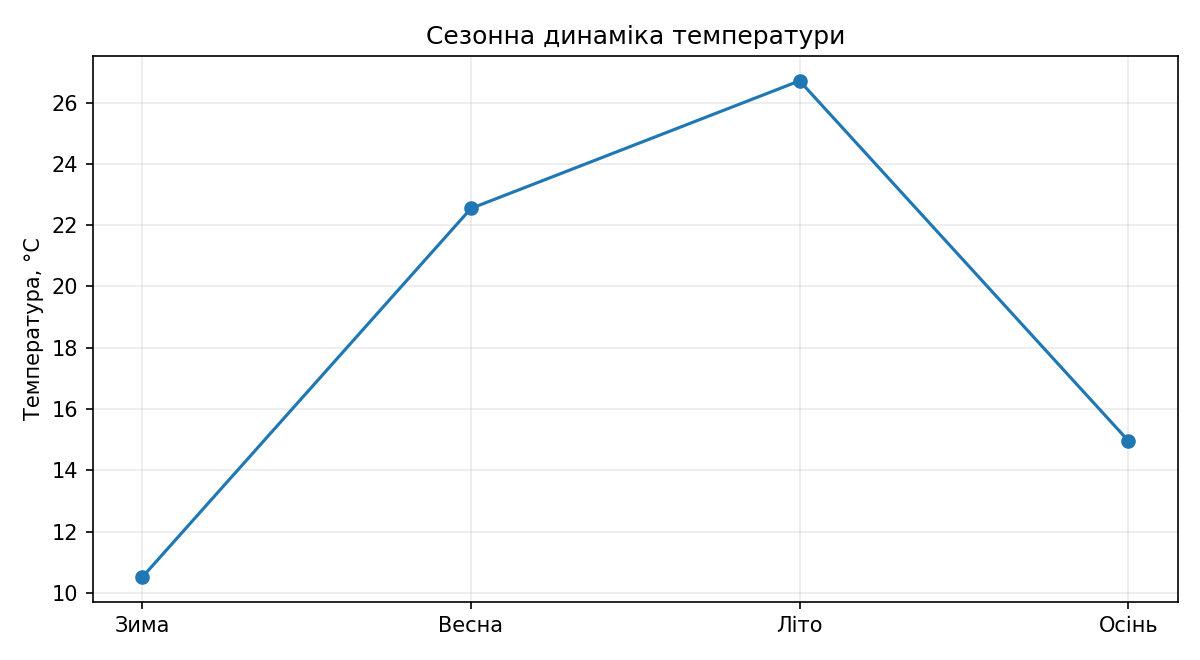

site_comparison.png


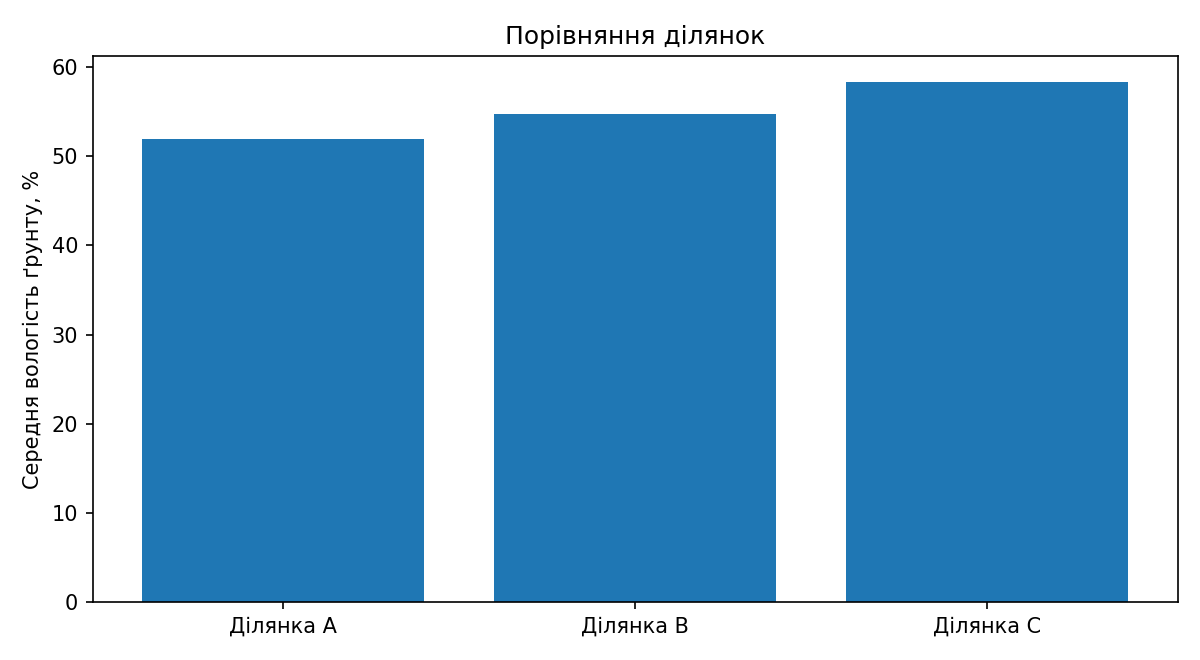

ph_histogram.png


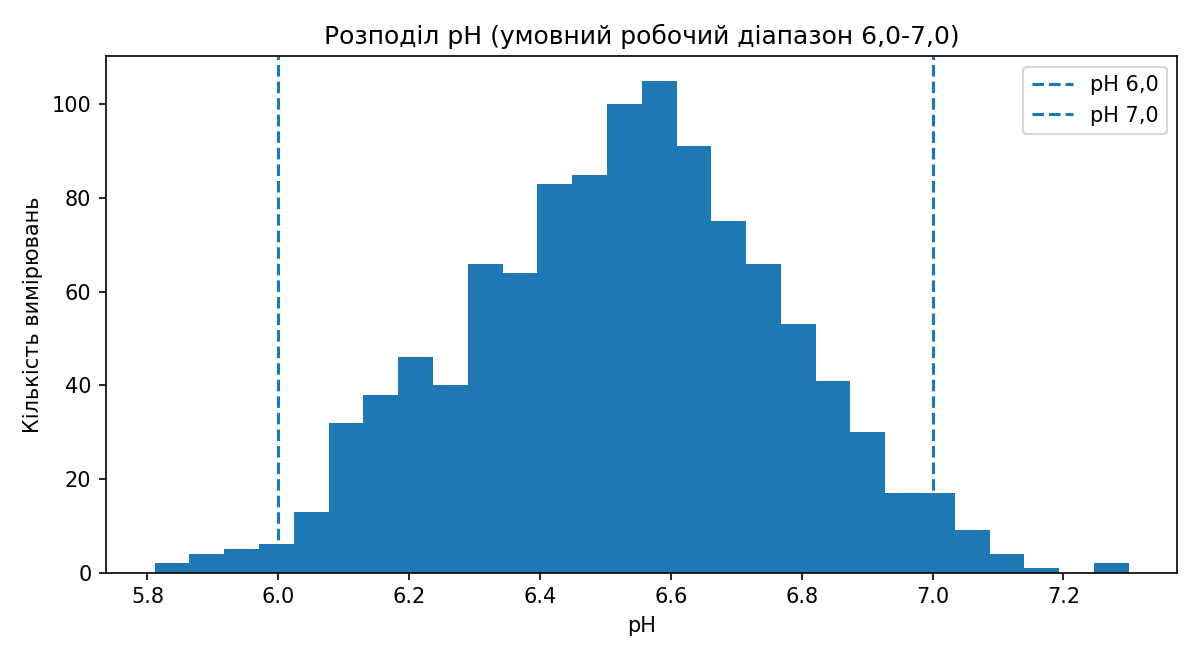

temperature_moisture.png


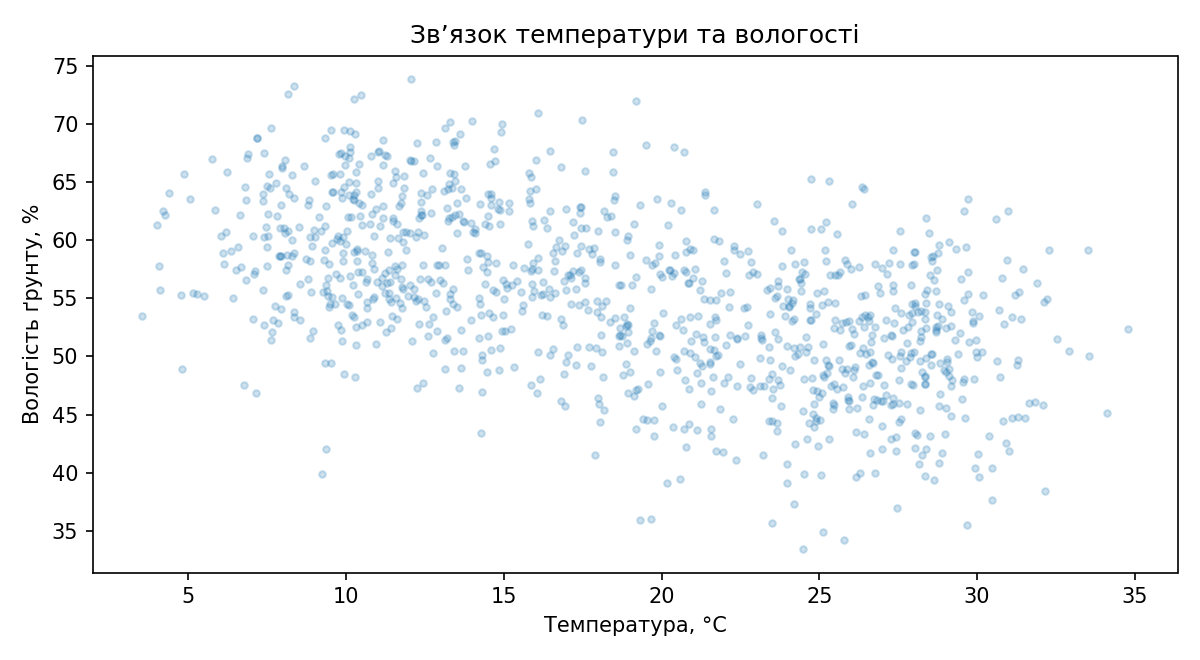

In [8]:
from IPython.display import display, Image
for name in ['seasonal_temperature.png','site_comparison.png','ph_histogram.png','temperature_moisture.png']:
    print(name)
    display(Image(filename='/content/results/'+name))

### 5. Порівняння стиснення та локальне відновлення

In [9]:
import json, gzip, zlib, bz2, hashlib
from pathlib import Path
with open('/content/results/compression.json', encoding='utf8') as f: summary=json.load(f)
table=pd.DataFrame.from_dict(summary['algorithms'],orient='index')
display(table.round(2))
best=summary['best']
blob=Path('/content/results/cleaned.json.'+{'gzip':'gz','zlib':'zlib','bzip2':'bz2'}[best]).read_bytes()
original=clean.to_json(orient='records',force_ascii=False).encode('utf8')
restored={'gzip':gzip.decompress,'zlib':zlib.decompress,'bzip2':bz2.decompress}[best](blob)
assert restored == original
print('Оптимальний алгоритм:',best)
print('Байтове відновлення без втрат:',restored==original)
print('SHA-256:',hashlib.sha256(restored).hexdigest())

,bytes,ratio,saving_pct
gzip,22449,8.78,88.61
zlib,22437,8.78,88.62
bzip2,15080,13.07,92.35


Оптимальний алгоритм: bzip2
Байтове відновлення без втрат: True
SHA-256: 503c966fe7d2684d3ef879cde6af0a84e775bef663f66962f9cda55f43f6f348


### 6. Реальне завантаження **стисненого** пакета у Firebase

Перед цим вручну завантажте службовий JSON у Files. **Не друкуйте вивід JSON, не вставляйте приватний ключ у ячейки.** Рекомендовано зберігати лише цей блокнот без JSON у репозиторії. Віддалене виконання вимагає власного проєкту Firebase.

In [10]:
import glob
keys = glob.glob('/content/*firebase-adminsdk*.json')
assert len(keys)==1, 'Завантажте рівно один службовий JSON-ключ Firebase у Files'
cloud_env=os.environ.copy()
cloud_env['FIREBASE_SERVICE_ACCOUNT_JSON']=keys[0]
cloud_env['FIREBASE_DATABASE_URL']='https://rgr-iot-variant-2-default-rtdb.europe-west1.firebasedatabase.app'
result=subprocess.run(['python',str(script)],cwd='/content',env=cloud_env,capture_output=True,text=True)
print(result.stdout[-600:])
if result.returncode:
    print('Завантаження не пройшло; перевірте мережу, права Firebase і шлях до JSON.')
    print(result.stderr[-1200:])
assert result.returncode == 0, 'Firebase: збій у перевірці'

   6.34
Ділянка B          18.93              54.73         11603.01     6.54
Ділянка C          19.31              58.33         11269.81     6.71

Стиснення:
{
  "gzip": {
    "bytes": 22449,
    "ratio": 8.779,
    "saving_pct": 88.61
  },
  "zlib": {
    "bytes": 22437,
    "ratio": 8.784,
    "saving_pct": 88.62
  },
  "bzip2": {
    "bytes": 15080,
    "ratio": 13.069,
    "saving_pct": 92.35
  }
}

ПРИМІТКА: усі показники синтетичні, а pH 6,0-7,0 - демонстраційна уставка, не універсальна агрономічна норма.
FIREBASE VERIFIED: 1095 records; bzip2 ; SHA-256 OK
Результати: /content/results



### 7. Перевірка **зворотного** отримання зі стисненого пакета Firebase

In [11]:
with open('/content/results/firebase_verification.json', encoding='utf8') as f: verification=json.load(f)
display(pd.DataFrame([verification]))
assert verification['cloud_transfer']=='success' and verification['byte_identical']
with open('/content/results/firebase_download.json', encoding='utf8') as f: downloaded=json.load(f)
df_cloud=pd.DataFrame(downloaded)
assert len(df_cloud)==1095
print('З Firebase відновлено записів:',len(df_cloud))
display(df_cloud.head())

,cloud_transfer,algorithm,record_count,original_bytes,compressed_bytes,sha256,byte_identical
0,success,bzip2,1095,197076,15080,503c966fe7d2684d3ef879cde6af0a84e775bef663f669...,True


З Firebase відновлено записів: 1095


,date,site,soil_moisture_pct,temperature_c,illuminance_lux,soil_ph,season,ph_optimal
0,2025-01-01,Ділянка A,59.091,6.363,287.998,6.615,Зима,True
1,2025-01-02,Ділянка A,59.386,7.504,4061.595,6.307,Зима,True
2,2025-01-03,Ділянка A,57.417,8.112,5077.304,6.233,Зима,True
3,2025-01-04,Ділянка A,50.948,10.325,3641.748,6.475,Зима,True
4,2025-01-05,Ділянка A,54.228,12.539,7874.956,6.116,Зима,True


### 8. Збереження підтверджень для звіту

In [12]:
!cd /content && zip -qr RGR_verified_results.zip results
from google.colab import files
files.download('/content/RGR_verified_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Висновок

Експеримент підтверджує можливість моделювання IoT-даних, попередньої Edge-обробки, зберігання в реляційній SQLite та порівняння методів стиснення. Хмарний етап реалізує передачу **саме стисненого** пакета з метаданими, отримання назад, розпакування, перевірку SHA-256 і кількості записів. Фактичні результати віддаленої перевірки слід фіксувати **після** запуску ячейок 6–7 у власному Colab; до цього підтверджено лише локальну працездатність.